<a href="https://colab.research.google.com/github/piihutanoch/pet-breed-classifier/blob/main/notebooks/03_finetune.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json, sys, time
import torch

Mounted at /content/drive


In [2]:
project_dir= Path("/content/drive/MyDrive/pet-breed-classifier")
artifacts_dir= project_dir/"artifacts"
src_dir= project_dir/"src"            # reusable .py files live here
data_dir= Path("/content/data")

artifacts_dir.mkdir(parents=True, exist_ok=True)
src_dir.mkdir(parents=True, exist_ok= True)
data_dir.mkdir(parents=True, exist_ok= True)

In [3]:
seed= 42
torch.manual_seed(seed)

# Select GPU when CUDA is available
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


In [4]:
!wget -q --show-progress https://s3.amazonaws.com/fast-ai-imageclas/oxford-iiit-pet.tgz -O /content/pets.tgz
!tar -xzf /content/pets.tgz -C /content/data
!ls /content/data/oxford-iiit-pet

/content/pets.tgz   100%[===================>] 774.10M  36.3MB/s    in 19s     
annotations  images


In [5]:
# Load the previously saved training and validation indices
with open(artifacts_dir/"splits.json") as f:
    splits= json.load(f)

train_idx= splits["train"]
val_idx= splits["val"]

# Load the numerical index-to-breed mapping
with open(artifacts_dir/"classes.json") as f:
    idx_to_class= json.load(f)

print("train:", len(train_idx), "val:", len(val_idx))   # 3128, 552
print("class 0:", idx_to_class["0"])

train: 3128 val: 552
class 0: Abyssinian


In [6]:
print(type(train_idx))
print(train_idx[:10])
print(len(train_idx))

<class 'list'>
[25, 2592, 3318, 3060, 411, 2433, 89, 3401, 2246, 2956]
3128


In [7]:

%%writefile /content/drive/MyDrive/pet-breed-classifier/src/data.py

from torchvision import transforms
from torchvision.datasets import OxfordIIITPet
from torch.utils.data import Subset, DataLoader

# ImageNet RGB channel statistics for normalisation
IMAGENET_MEAN= [0.485, 0.456, 0.406]
IMAGENET_STD= [0.229, 0.224, 0.225]


def get_eval_transform():
    """Deterministic preprocessing for validation, testing and inference."""
    return transforms.Compose([
        transforms.Resize(256),       # Resize shorter side while preserving aspect ratio
        transforms.CenterCrop(224),  # Crop a fixed 224x224 region from the centre
        transforms.ToTensor(),       # Convert image to tensor and scale pixels to [0, 1]
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])


def get_train_transform():
    """Apply random augmentations to training images."""
    return transforms.Compose([
        # Randomly crop and resize to introduce variation in image framing
        transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),

        # Flip images horizontally with a 50% probability
        transforms.RandomHorizontalFlip(),

        # Introduce variation in brightness, contrast and saturation
        transforms.ColorJitter(
            brightness=0.2, contrast=0.2, saturation=0.2
        ),

        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])


def get_loaders(data_dir, train_idx, val_idx, batch_size=32):

    # Create dataset objects with separate training and evaluation transforms
    train_base= OxfordIIITPet(
        root=data_dir,
        split="trainval",
        target_types="category",
        transform=get_train_transform()
    )

    val_base= OxfordIIITPet(
        root=data_dir,
        split="trainval",
        target_types="category",
        transform=get_eval_transform()
    )

    # Select the previously saved training and validation indices
    train_ds= Subset(train_base, train_idx)
    val_ds= Subset(val_base, val_idx)

    # Create batches; shuffle training data but keep validation order fixed
    train_loader= DataLoader(
        train_ds, batch_size=batch_size,
        shuffle=True, num_workers=2
    )

    val_loader= DataLoader(
        val_ds, batch_size=batch_size,
        shuffle=False, num_workers=2
    )

    return train_loader, val_loader


Overwriting /content/drive/MyDrive/pet-breed-classifier/src/data.py


### Data Pipeline with Augmentation

The data pipeline is updated to introduce random augmentation during training while retaining deterministic preprocessing for validation.

Training images undergo random resized cropping, horizontal flipping and colour adjustments to increase visual variation and improve generalisation. Both training and validation images are converted to tensors and normalised using ImageNet statistics to remain compatible with the pretrained EfficientNet model.

The previously saved training and validation indices are reused to preserve the original dataset split. Separate DataLoaders are created to supply batches for training and evaluation.

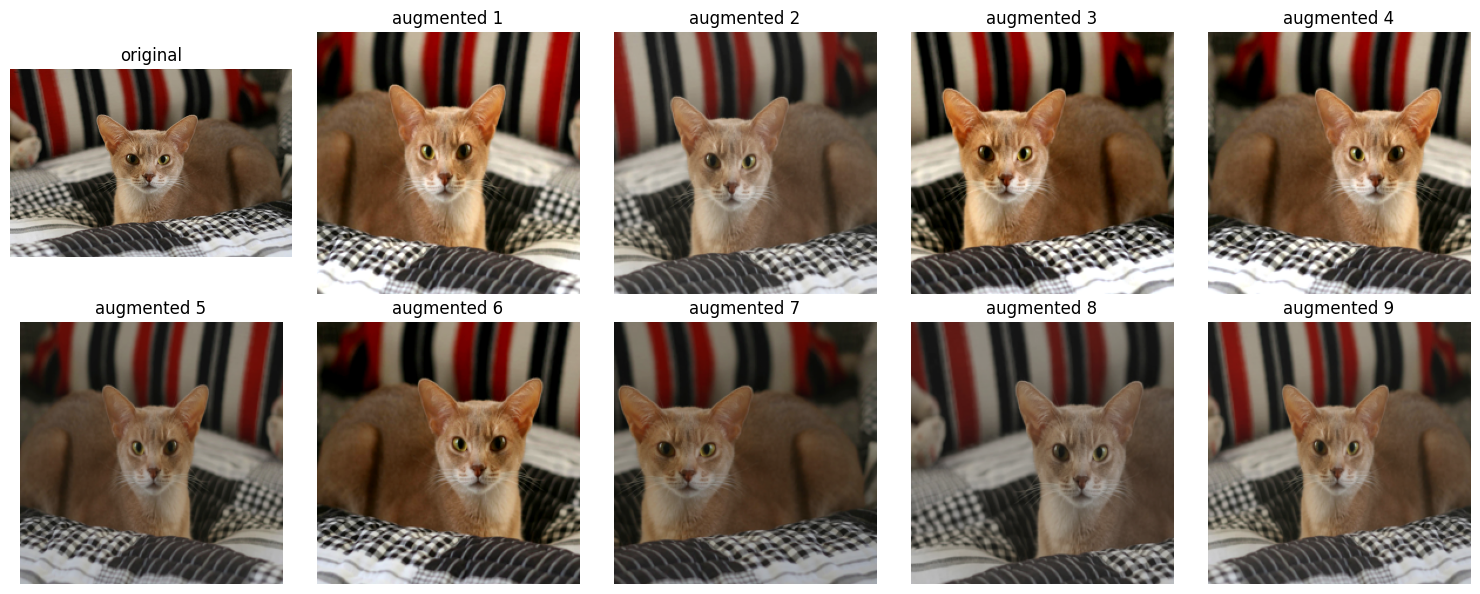

In [8]:
import importlib
sys.path.append(str(project_dir))

import src.data
importlib.reload(src.data)  # Reload updated data.py with augmentation

from src.data import get_loaders, get_train_transform, IMAGENET_MEAN, IMAGENET_STD
from torchvision.datasets import OxfordIIITPet
import matplotlib.pyplot as plt

# Load the dataset without transformations to access the original PIL image
raw_ds= OxfordIIITPet(
    root=data_dir, split="trainval", target_types="category"
)
img, label= raw_ds[train_idx[0]]  # Retrieve the first training image and its label

train_tfm= get_train_transform()

# Prepare ImageNet statistics for reversing normalisation during display
mean= torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std= torch.tensor(IMAGENET_STD).view(3, 1, 1)

# Create a grid for the original image and nine augmented versions
fig, axes= plt.subplots(2, 5, figsize=(15, 6))
axes= axes.flatten()

axes[0].imshow(img)
axes[0].set_title("original")

for i in range(1, 10):
    x= train_tfm(img)           # Apply a fresh random augmentation
    x= x * std + mean           # Reverse normalisation for visualisation
    x= x.clamp(0, 1)            # Keep pixel values within [0, 1]

    # Convert from CHW to HWC format for Matplotlib
    axes[i].imshow(x.permute(1, 2, 0))
    axes[i].set_title(f"augmented {i}")

# Hide axes and display the image grid
for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


### Visualising Data Augmentation

A sample training image is loaded without transformations and passed through the training augmentation pipeline multiple times. The resulting variations are displayed alongside the original image to verify that random cropping, horizontal flipping and colour adjustments are working as intended.

Normalisation is reversed temporarily for visualisation, and the tensor dimensions are rearranged to match Matplotlib's expected image format. This check helps ensure that the augmentations introduce useful variation without excessively distorting the original images.

In [9]:
%%writefile /content/drive/MyDrive/pet-breed-classifier/src/model.py

import torch.nn as nn
from torchvision import models


def build_model(name="efficientnet_b0", num_classes=37, freeze=True):

    if name== "efficientnet_b0":
        # Load EfficientNet-B0 with pretrained ImageNet weights
        model= models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT
        )

        if freeze:
            # Freeze pretrained parameters before replacing the classifier
            for param in model.parameters():
                param.requires_grad= False

        # Replace the original 1000-class head with a 37-class classifier
        in_features= model.classifier[1].in_features  # 1280
        model.classifier[1]= nn.Linear(in_features, num_classes)

    elif name== "resnet50":
        # Load ResNet50 with pretrained ImageNet weights
        model= models.resnet50(
            weights=models.ResNet50_Weights.DEFAULT
        )

        if freeze:
            # Freeze pretrained parameters before replacing the classifier
            for param in model.parameters():
                param.requires_grad= False

        # Replace the original 1000-class head with a 37-class classifier
        in_features= model.fc.in_features  # 2048
        model.fc= nn.Linear(in_features, num_classes)

    else:
        raise ValueError(f"Unknown model name: {name}")

    return model


# Prefixes used to identify classifier parameters in each architecture
HEAD_PREFIX = {
    "efficientnet_b0": "classifier.",
    "resnet50": "fc."
}


def split_params(model, name):
    """Separate backbone and classification head parameters."""

    backbone, head= [], []

    # Retrieve each parameter along with its name
    for param_name, param in model.named_parameters():

        # Group parameters based on their layer names
        if param_name.startswith(HEAD_PREFIX[name]):
            head.append(param)
        else:
            backbone.append(param)

    return backbone, head


Overwriting /content/drive/MyDrive/pet-breed-classifier/src/model.py


### Model Architecture and Parameter Grouping

The model builder is extended to support both EfficientNet-B0 and ResNet50 using pretrained ImageNet weights. Their original classification layers are replaced with new layers that output predictions for 37 pet breeds.

An optional freezing mechanism allows pretrained parameters to remain unchanged while the newly added classification head stays trainable.

The split_params() function separates backbone and classification head parameters using their layer names. This enables different learning rates to be assigned to the pretrained feature extractor and the newly initialised classifier during fine-tuning.

In [10]:
def train_one_epoch(model, loader, loss_fn, optimizer, device):
    model.train()  # Enable training behaviour (e.g. dropout)
    total_loss, correct, count = 0.0, 0, 0

    for images, labels in loader:
        # Move the batch to the same device as the model
        images= images.to(device)
        labels= labels.to(device)

        # Forward pass: generate logits for all 37 classes
        outputs= model(images)
        loss= loss_fn(outputs, labels)

        # Backpropagation and weight update
        optimizer.zero_grad()  # Clear gradients from the previous batch
        loss.backward()        # Calculate gradients for trainable parameters
        optimizer.step()       # Update trainable weights

        # Accumulate loss and correct predictions across batches
        batch_size= images.size(0)
        total_loss+= loss.item() * batch_size  # Convert batch mean loss to total
        preds= outputs.argmax(dim=1)           # Select the highest-scoring class
        correct+= (preds== labels).sum().item()
        count+= batch_size

    return total_loss/count, correct/count

In [11]:
def evaluate(model, loader, loss_fn, device):
    model.eval()  # Disable training-specific behaviour (e.g. dropout)
    total_loss, correct, count = 0.0, 0, 0

    # Disable gradient tracking since no weight updates are needed
    with torch.no_grad():
        for images, labels in loader:
            images= images.to(device)
            labels= labels.to(device)

            # Generate predictions and calculate loss
            outputs= model(images)
            loss= loss_fn(outputs, labels)

            # Accumulate loss and accuracy across batches
            batch_size= images.size(0)
            total_loss+= loss.item()*batch_size
            preds= outputs.argmax(dim=1)
            correct+= (preds==labels).sum().item()
            count+= batch_size

    return total_loss / count, correct / count

In [12]:
import importlib
import src.model
importlib.reload(src.model)

from src.model import build_model, split_params
import torch.nn as nn
import os


def run_experiment(name, num_epochs= 12, patience= 3,
                   backbone_lr= 1e-4, head_lr= 1e-3, batch_size= 32):

    # Set random seed and create augmented training/validation loaders
    torch.manual_seed(seed)
    train_loader, val_loader= get_loaders(
        data_dir, train_idx, val_idx, batch_size= batch_size
    )

    # Load pretrained model with all parameters trainable
    model= build_model(name, num_classes=37, freeze=False).to(device)

    # Separate backbone and classifier parameters for different learning rates
    backbone_params, head_params= split_params(model, name)

    # Assign a smaller learning rate to pretrained layers
    # and a larger learning rate to the new classification head
    optimizer = torch.optim.AdamW([
        {"params": backbone_params, "lr": backbone_lr},
        {"params": head_params, "lr": head_lr},
    ])

    # Gradually reduce learning rates using a cosine schedule
    scheduler= torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max= num_epochs
    )

    # Apply label smoothing to reduce overconfident predictions
    loss_fn= nn.CrossEntropyLoss(label_smoothing=0.1)

    # Set up checkpoint path and containers for experiment metrics
    ckpt_path= artifacts_dir/f"finetuned_{name}.pt"
    history= {
        "train_loss": [], "train_acc": [],
        "val_loss": [], "val_acc": [], "epoch_time": []
    }

    best_val_acc= 0.0
    best_epoch= 0
    epochs_without_improvement= 0

    for epoch in range(1, num_epochs+1):
        start= time.time()

        # Train the model and evaluate it on the validation set
        train_loss, train_acc= train_one_epoch(
            model, train_loader, loss_fn, optimizer, device
        )
        val_loss, val_acc= evaluate(
            model, val_loader, loss_fn, device
        )

        # Update learning rates for the next epoch
        scheduler.step()
        epoch_time = time.time()-start

        # Record metrics for later analysis and plotting
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["epoch_time"].append(epoch_time)

        print(f"[{name}] Epoch {epoch}/{num_epochs} | "
              f"train loss {train_loss:.3f} acc {train_acc:.3f} | "
              f"val loss {val_loss:.3f} acc {val_acc:.3f} | {epoch_time:.0f}s")

        # Save the checkpoint whenever validation accuracy improves
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch
            epochs_without_improvement = 0
            torch.save(model.state_dict(), ckpt_path)
            print(" -> new best, checkpoint saved")

        else:
            # Stop training after consecutive epochs without improvement
            epochs_without_improvement += 1

            if epochs_without_improvement >= patience:
                print(f" early stopping: no improvement for {patience} epochs")
                break

    # Save the complete training history
    with open(artifacts_dir/f"history_{name}.json", "w") as f:
        json.dump(history, f)

    # Return a summary of the experiment for model comparison
    return {
        "run": "Fine-tuned",
        "backbone": name,
        "frozen": "No",
        "augmentation": "Yes",
        "val_acc": best_val_acc,
        "best_epoch": best_epoch,
        "sec_per_epoch": sum(history["epoch_time"]) / len(history["epoch_time"]),
        "size_mb": os.path.getsize(ckpt_path) / 1e6,
        "history": history,
    }


In [13]:
results = {}
results["efficientnet_b0"] = run_experiment("efficientnet_b0", num_epochs=12)
print("\nBest val acc:", round(results["efficientnet_b0"]["val_acc"], 4),
      "at epoch", results["efficientnet_b0"]["best_epoch"])

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 109MB/s] 


[efficientnet_b0] Epoch 1/12 | train loss 1.968 acc 0.643 | val loss 1.066 acc 0.899 | 33s
   ↳ new best, checkpoint saved
[efficientnet_b0] Epoch 2/12 | train loss 1.059 acc 0.903 | val loss 0.996 acc 0.918 | 30s
   ↳ new best, checkpoint saved
[efficientnet_b0] Epoch 3/12 | train loss 0.927 acc 0.947 | val loss 0.945 acc 0.931 | 30s
   ↳ new best, checkpoint saved
[efficientnet_b0] Epoch 4/12 | train loss 0.875 acc 0.966 | val loss 0.936 acc 0.926 | 30s
[efficientnet_b0] Epoch 5/12 | train loss 0.836 acc 0.974 | val loss 0.914 acc 0.935 | 29s
   ↳ new best, checkpoint saved
[efficientnet_b0] Epoch 6/12 | train loss 0.804 acc 0.987 | val loss 0.923 acc 0.929 | 29s
[efficientnet_b0] Epoch 7/12 | train loss 0.790 acc 0.991 | val loss 0.907 acc 0.931 | 36s
[efficientnet_b0] Epoch 8/12 | train loss 0.780 acc 0.991 | val loss 0.907 acc 0.929 | 30s
 early stopping: no improvement for 3 epochs

Best val acc: 0.9348 at epoch 5


In [14]:
results["resnet50"] = run_experiment("resnet50", num_epochs=12)
print("\nBest val acc:", round(results["resnet50"]["val_acc"], 4),
      "at epoch", results["resnet50"]["best_epoch"])

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 176MB/s]


[resnet50] Epoch 1/12 | train loss 1.618 acc 0.733 | val loss 0.944 acc 0.940 | 40s
   ↳ new best, checkpoint saved
[resnet50] Epoch 2/12 | train loss 0.867 acc 0.951 | val loss 0.885 acc 0.947 | 38s
   ↳ new best, checkpoint saved
[resnet50] Epoch 3/12 | train loss 0.785 acc 0.978 | val loss 0.874 acc 0.946 | 40s
[resnet50] Epoch 4/12 | train loss 0.745 acc 0.988 | val loss 0.849 acc 0.949 | 38s
   ↳ new best, checkpoint saved
[resnet50] Epoch 5/12 | train loss 0.725 acc 0.993 | val loss 0.843 acc 0.940 | 39s
[resnet50] Epoch 6/12 | train loss 0.713 acc 0.995 | val loss 0.841 acc 0.951 | 40s
   ↳ new best, checkpoint saved
[resnet50] Epoch 7/12 | train loss 0.705 acc 0.997 | val loss 0.842 acc 0.946 | 40s
[resnet50] Epoch 8/12 | train loss 0.696 acc 0.998 | val loss 0.828 acc 0.949 | 40s
[resnet50] Epoch 9/12 | train loss 0.692 acc 0.998 | val loss 0.828 acc 0.947 | 38s
 early stopping: no improvement for 3 epochs

Best val acc: 0.9511 at epoch 6


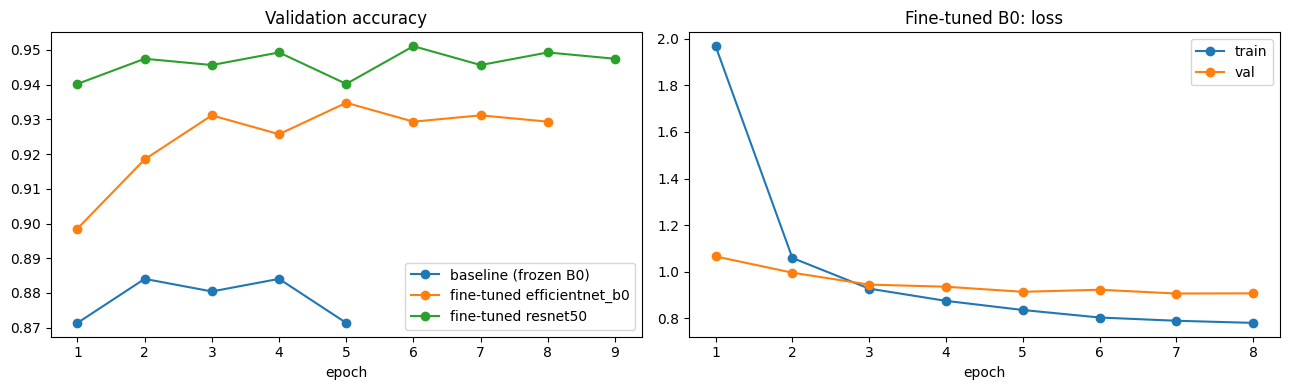

In [15]:
with open(artifacts_dir / "baseline_history.json") as f:
    base_hist= json.load(f)

fig, (ax1, ax2)= plt.subplots(1, 2, figsize=(13, 4))

# Left: validation accuracy of all runs
ax1.plot(range(1, len(base_hist["val_acc"])+ 1), base_hist["val_acc"], marker="o", label="baseline (frozen B0)")
for name in results:
    h= results[name]["history"]
    ax1.plot(range(1, len(h["val_acc"])+ 1), h["val_acc"], marker= "o", label=f"fine-tuned {name}")
ax1.set_title("Validation accuracy"); ax1.set_xlabel("epoch"); ax1.legend()

# Right: train vs val loss for fine-tuned B0 (overfitting check)
h = results["efficientnet_b0"]["history"]
ax2.plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], marker="o", label="train")
ax2.plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], marker="o", label="val")
ax2.set_title("Fine-tuned B0: loss"); ax2.set_xlabel("epoch"); ax2.legend()

plt.tight_layout()
plt.savefig(artifacts_dir / "finetune_curves.png", dpi=120)
plt.show()

### Fine-Tuning Results and Performance Comparison

The fine-tuned EfficientNet-B0 and ResNet50 models are compared against the frozen EfficientNet-B0 baseline using validation accuracy.

Both fine-tuned models achieve substantially higher validation accuracy than the baseline. Fine-tuned EfficientNet-B0 reaches approximately 93.5%, while ResNet50 achieves approximately 95.1%. This indicates that allowing pretrained layers to adapt to the pet breed dataset improves classification performance.

The loss curves for EfficientNet-B0 show a steady decrease in training loss, indicating that the model is learning from the training data. Validation loss also decreases initially before stabilising, while validation accuracy fluctuates slightly across epochs.

Overall, fine-tuning improves validation performance, with ResNet50 achieving the highest validation accuracy among the three experiments.

In [18]:
# Extract the highest validation accuracy achieved by the baseline
baseline_best= max(base_hist["val_acc"])

# Create a summary dictionary for the baseline experiment
baseline_row= {
    "run": "Baseline",
    "backbone": "efficientnet_b0",
    "frozen": "Yes",
    "augmentation": "No",
    "val_acc": baseline_best,

    # Convert the zero-based list position into a one-based epoch number
    "best_epoch": base_hist["val_acc"].index(baseline_best) + 1,

    # Calculate average training time per epoch
    "sec_per_epoch": sum(base_hist["epoch_time"]) / len(base_hist["epoch_time"]),

    # Retrieve checkpoint size and convert bytes to MB
    "size_mb": os.path.getsize(artifacts_dir / "baseline_b0.pt") / 1e6,
}

# Start the comparison list with the baseline results
rows = [baseline_row]

# Add the summary results from each fine-tuning experiment
for name in results:
    row = dict(results[name])  # Create a copy of the experiment results
    del row["history"]         # Exclude per-epoch metrics from the summary table
    rows.append(row)

# Convert experiment dictionaries into a Pandas DataFrame
table = pd.DataFrame(rows)

# Format values for easier comparison
table["val_acc"] = (table["val_acc"] * 100).round(2)  # Accuracy as percentage
table["sec_per_epoch"] = table["sec_per_epoch"].round(0)
table["size_mb"] = table["size_mb"].round(1)

# Print Markdown output for the project results documentation
print(table.to_markdown(index=False))

# Display the formatted comparison table
table


| run        | backbone        | frozen   | augmentation   |   val_acc |   best_epoch |   sec_per_epoch |   size_mb |
|:-----------|:----------------|:---------|:---------------|----------:|-------------:|----------------:|----------:|
| Baseline   | efficientnet_b0 | Yes      | No             |     88.41 |            2 |              21 |      16.5 |
| Fine-tuned | efficientnet_b0 | No       | Yes            |     93.48 |            5 |              31 |      16.5 |
| Fine-tuned | resnet50        | No       | Yes            |     95.11 |            6 |              39 |      94.7 |


,run,backbone,frozen,augmentation,val_acc,best_epoch,sec_per_epoch,size_mb
0,Baseline,efficientnet_b0,Yes,No,88.41,2,21.0,16.5
1,Fine-tuned,efficientnet_b0,No,Yes,93.48,5,31.0,16.5
2,Fine-tuned,resnet50,No,Yes,95.11,6,39.0,94.7


In [19]:
import shutil

# Retrieve the best validation accuracy from each experiment
b0_acc= results["efficientnet_b0"]["val_acc"]
r50_acc= results["resnet50"]["val_acc"] if "resnet50" in results else 0.0

# Prefer the smaller, faster model unless ResNet50 improves accuracy
# by more than 0.5 percentage points
if r50_acc-b0_acc > 0.005:
    final_name = "resnet50"
else:
    final_name = "efficientnet_b0"

print("Final model:", final_name)

# Copy the selected checkpoint to the standard filename expected by the app
shutil.copy(
    artifacts_dir/f"finetuned_{final_name}.pt",
    artifacts_dir/"model.pt"
)

# Save architecture details and validation accuracy for model reconstruction
with open(artifacts_dir/"model_config.json", "w") as f:
    json.dump({
        "name": final_name,
        "num_classes": 37,
        "val_acc": results[final_name]["val_acc"]
    }, f, indent=2)

# Rebuild the selected architecture and load its saved parameters
final_model = build_model(
    final_name, num_classes=37, freeze=False
).to(device)

final_model.load_state_dict(
    torch.load(artifacts_dir / "model.pt", map_location=device)
)

# Recreate the validation loader and evaluate the reloaded model
_, val_loader = get_loaders(data_dir, train_idx, val_idx)

_, reloaded_acc = evaluate(
    final_model, val_loader, nn.CrossEntropyLoss(), device
)

# Compare the original and reloaded model performance
print(
    "expected:", round(results[final_name]["val_acc"], 4),
    "reloaded:", round(reloaded_acc, 4)
)

# Verify that the saved checkpoint reproduces the expected accuracy
assert abs(reloaded_acc - results[final_name]["val_acc"]) < 0.002

print("model.pt saved and verified.")


Final model: resnet50
expected: 0.9511 reloaded: 0.9511
model.pt saved and verified.
